In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import squarify

In [2]:
df = pd.read_csv('age_salary_hours.csv')

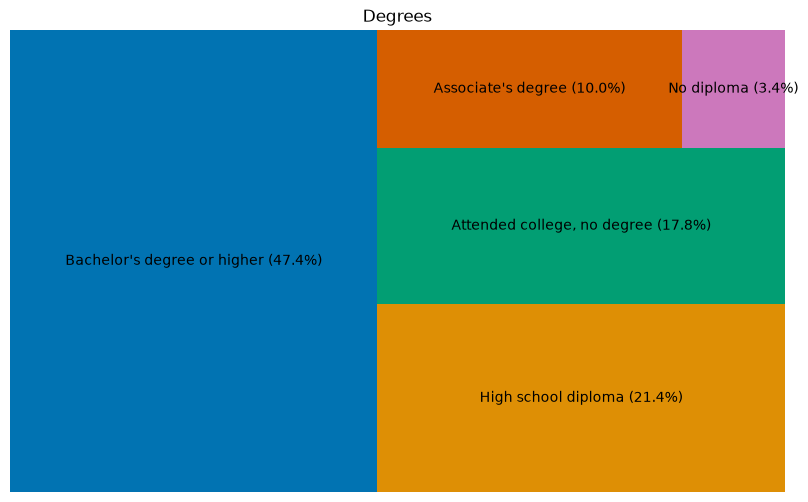

In [3]:
edu_counts = df['Education'].value_counts()
edu_percentages = (edu_counts / len(df)) * 100

edu_percentages = edu_percentages.sort_values(ascending=False)

labels = [f"{edu} ({pct:.1f}%)" for edu, pct in zip(edu_percentages.index, edu_percentages.values)]

plt.figure(figsize=(10, 6))

squarify.plot(sizes=edu_percentages.values, 
              label=labels, 
              color=sns.color_palette("colorblind", len(edu_percentages)))

plt.axis('off')

plt.title('Degrees')
plt.show()

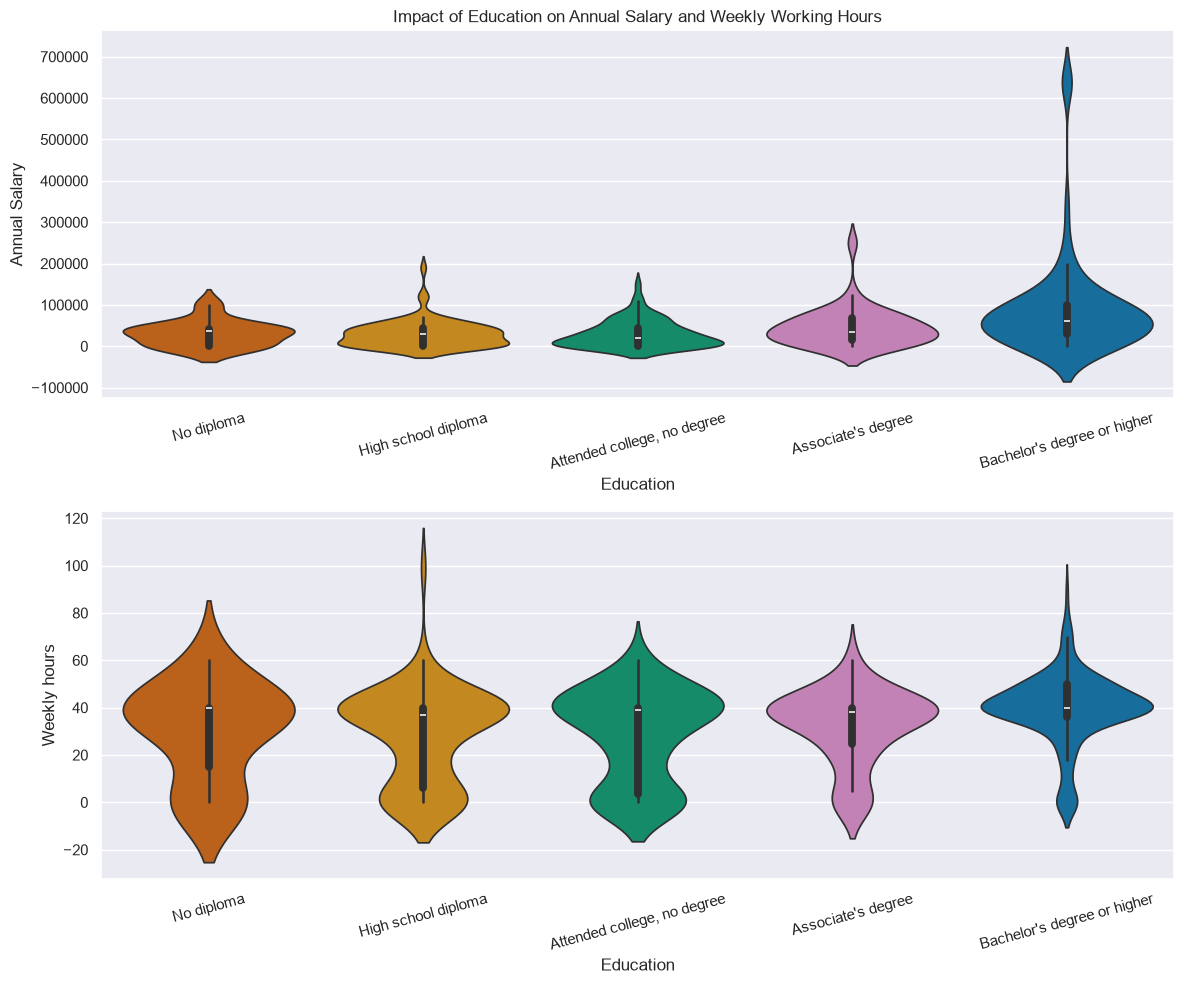

In [4]:
df_filtered = df[df['Age'] < 65]

edu_order = ["No diploma", "High school diploma", "Attended college, no degree", 
             "Associate's degree", "Bachelor's degree or higher"]

sns.set_theme(style="darkgrid")

fig, axes = plt.subplots(2, 1, figsize=(12, 10))

sns.violinplot(x='Education', y='Annual Salary', data=df_filtered, 
               order=edu_order, palette='colorblind', 
               hue='Education', legend=False, ax=axes[0])

axes[0].set_title('Impact of Education on Annual Salary and Weekly Working Hours')
axes[0].set_xlabel('Education')
axes[0].set_ylabel('Annual Salary')
axes[0].tick_params(axis='x', rotation=15)

sns.violinplot(x='Education', y='Weekly hours', data=df_filtered, 
               order=edu_order, palette='colorblind', 
               hue='Education', legend=False, ax=axes[1])

axes[1].set_xlabel('Education')
axes[1].set_ylabel('Weekly hours')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()